# Л3 — Рішення з ціною помилки

Модель класифікації дає ймовірність події, наприклад відмови обладнання. Щоб із цього вийшло рішення — висилати бригаду чи ні, — модель має вчитися на чесних даних, а поріг має враховувати ціну кожної помилки.

Ноутбук нижче проходить цей шлях на одній задачі, спрощено. Більше туторіалів — у [Kaggle Learn](https://www.kaggle.com/learn), зокрема [Intro to Machine Learning](https://www.kaggle.com/learn/intro-to-machine-learning) та [Intermediate Machine Learning](https://www.kaggle.com/learn/intermediate-machine-learning) з уроками про витік даних, pipelines і крос-валідацію.

Типовий шлях задачі класифікації (у дужках — кроки цього ноутбука):

- зрозуміти дані (1);
- перевірити, чи дані чесні: витік, зміщена вибірка, data drift (2–4);
- підготувати ознаки: кодування категорій, масштабування (5). У реальних проєктах ці перетворення збирають у pipeline, щоб до нових даних застосовувались ті самі кроки; тут вони написані вручну;
- розділити дані на навчальну й валідаційну частини (5). Часто замість однієї валідаційної частини беруть крос-валідацію; тут її немає;
- порівняти кілька моделей (6);
- підібрати гіперпараметри (7). Зазвичай це перебір за сіткою з крос-валідацією (`GridSearchCV`); тут лише одна крива для `alpha`;
- обрати поріг рішення під задачу (8);
- застосувати модель до нових даних (9) і далі стежити, чи не погіршилась вона з часом.

І головне: гарна метрика на валідації ще не гарантує, що модель працюватиме на нових даних. Якщо в даних є витік, зміщення чи зсув, модель виглядатиме добре, а рішення будуть поганими.

Інші часті проблеми даних, про які варто пам'ятати:

- **незбалансовані класи** — подія рідкісна, і частка правильних відповідей оманлива. Тут відмов 5–9%, тому моделі порівнюють за PR-AUC (крок 6);
- **замало даних** — модель запам'ятовує навчальні приклади замість закономірності; близьке явище видно на кривій перенавчання (крок 7);
- **пропуски й помилки в даних** — Л1;
- **помилки в мітках** — частину об'єктів позначено неправильно, і модель вчиться на цих помилках; тут цього немає;
- **зв'язок без причини** — ознака пов'язана з ціллю через третій чинник, а не напряму; Л2.

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Опис даних, вартості й таблиця пасток — у `README.md`.

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings('ignore', category=ConvergenceWarning)

## 1. Завантаження даних

Спершу подивіться, що всередині файлів: розмірність, колонки, типи й частку відмов у `train`. Можуть допомогти `df.head()`, `df.shape` і `df.dtypes`.

Вартості свого варіанта впишіть із таблиці в `README.md`: від них залежить правило рішення в кроці 8.

In [3]:
COST_VISIT   = 4080
COST_FAILURE = 48000

registry = pd.read_csv("./data/registry.csv")
train    = pd.read_csv("./data/train.csv")
test     = pd.read_csv("./data/test.csv")

print(f"registry: {registry.shape}, train: {train.shape}, test: {test.shape}")
print(f"failed rate: {train['failed'].mean():.2%}  ({train['failed'].sum()} / {len(train)})")
train.head(3)

registry: (6000, 8), train: (3975, 21), test: (2025, 20)
failed rate: 5.84%  (232 / 3975)


,object_id,load_mean,load_std,load_stability,load_weekend_ratio,temp_rise_mean,temp_rise_std,temp_rise_median,pd_mean,pd_std,...,pd_per_load,temp_per_load,equipment_type,voltage_class,region,install_year,last_overhaul_year,outdoor,failed,work_order_opened
0,EQ100003,84.808,9.729,0.8971,0.8185,12.808,0.748,12.93,31.129,7.519,...,0.3671,0.1510,transformer,kv6,north,1994,2018,1,0,0
1,EQ100004,60.581,8.572,0.8760,0.7805,14.160,0.931,14.13,29.237,5.195,...,0.4826,0.2337,switchgear,kv35,north,1989,2025,0,0,0
2,EQ100005,97.922,11.843,0.8921,0.8228,23.221,2.113,23.53,58.429,10.208,...,0.5967,0.2371,transformer,kv10,north,2018,2022,0,0,0


## 2. Витік (M-1)

Витік (data leakage) — колонка, значення якої стає відомим лише після того, що ми хочемо передбачити. Наприклад, у даних про відмови може бути колонка «вартість ремонту». Вона дуже точно «передбачає» відмову: ремонтують саме те, що зламалося. Але вартість ремонту з'являється вже після відмови, а рішення ухвалюють раніше, коли об'єкт ще працює й цього значення немає. Модель, навчена на такій колонці, на навчальних даних виглядає чудово, а на нових об'єктах не працює. Такі колонки прибирають.

Не завжди відомо, коли заповнюють кожну колонку, тож витік шукають за ознакою «надто добре вгадує». Для кожної колонки окремо рахують **ROC AUC** — ймовірність того, що у випадкового об'єкта, який відмовив, значення колонки більше, ніж у випадкового справного. 0.5 — колонка не відрізняє їх зовсім, як підкидання монети; 1 — відрізняє ідеально. Звичайна ознака на кшталт температури чи навантаження так точно не вгадує. Колонку з AUC понад 0.9 тут вважають витоком. У реальному проєкті висока AUC — привід з'ясувати, коли колонку заповнюють.

1. Для кожної числової колонки `train`, крім `failed`, порахуйте `roc_auc_score(train["failed"], колонка)`. Якщо AUC менше 0.5, візьміть 1 − AUC: колонка пов'язана з відмовою навпаки, у тих, що відмовили, значення менші.
2. Виведіть AUC усіх колонок від більшого до меншого.
3. Колонки з AUC більше 0.9 приберіть із `train` і `test`.

Можуть допомогти `select_dtypes("number")`, `sort_values` і `drop(columns=...)`.

In [4]:
num_cols = train.select_dtypes("number").columns.difference(["failed"])
aucs = {}
for c in num_cols:
    a = roc_auc_score(train["failed"], train[c])
    aucs[c] = a if a >= 0.5 else 1 - a

auc_series = pd.Series(aucs).sort_values(ascending=False)
print(auc_series.to_string())

leak_cols = auc_series[auc_series > 0.9].index.tolist()
print(f"\nВитік: {leak_cols}")
train = train.drop(columns=leak_cols)
test  = test.drop(columns=leak_cols, errors='ignore')

work_order_opened     0.971386
temp_rise_std         0.762402
temp_rise_mean        0.761204
temp_rise_median      0.761159
pd_std                0.709254
pd_mean               0.709249
load_mean             0.645728
temp_per_load         0.638788
load_std              0.634100
pd_per_load           0.592061
load_weekend_ratio    0.537745
install_year          0.537457
outdoor               0.520656
pd_stability          0.517123
load_stability        0.514970
last_overhaul_year    0.514432

Витік: ['work_order_opened']


## 3. Зміщена вибірка (M-2)

Завжди треба враховувати, як збирали дані. Наприклад, лікарня має дані переважно про людей, які прийшли з підозрою на хворобу: здорові приходять туди набагато рідше. Тож хворих у таких даних набагато більше, ніж серед усіх людей. Таке зміщення вибірки (selection bias) буває й в інших задачах: результат відомий не для всіх об'єктів, а переважно для тих, що вже викликали підозру.

Модель на таких даних усе ще може навчитися відрізняти ризикові об'єкти від решти. Але числа, пораховані на зміщеній вибірці, — частку подій, точність, ефект рішення — не можна переносити на всі об'єкти: вони будуть спотворені.

У цій задачі `registry.csv` містить усі об'єкти, а `train.csv` — лише ті об'єкти `history`, для яких відомо, чи вони відмовили.

Поділіть кількість рядків `train` на кількість об'єктів `registry` з `cohort == "history"` і виведіть частку; менше 0.9 — вибірка зміщена. Тоді виведіть ще середній `install_year` об'єктів `history`, що є в `train`, і об'єктів `history`, яких у `train` немає. Може допомогти `isin`.

У коді після цього нічого не змінюється: рішення будується так само, але частку відмов і ефект на валідації не можна переносити на всі об'єкти.

In [5]:
n_history = (registry["cohort"] == "history").sum()
ratio     = len(train) / n_history
print(f"train / history: {len(train)} / {n_history} = {ratio:.4f}")
print(f"M-2: {'зміщення є' if ratio < 0.9 else 'зміщення немає'} (поріг < 0.9)")

train / history: 3975 / 3975 = 1.0000
M-2: зміщення немає (поріг < 0.9)


## 4. Зсув у часі (M-3)

Властивості об'єктів змінюються з часом: люди старішають, обладнання зношується, датчик після калібрування чи заміни починає показувати інакше. Тому дані різних періодів можуть відрізнятися. Це називають **data drift** (зсув даних). Коли ж змінюється сам зв'язок ознак із ціллю, це **concept drift**; тут його немає.

Проблема виникає, коли зсув не врахували. Модель вивчила, що звичайна температура — 40 °C, а в нових даних датчик показує 45 °C для таких самих об'єктів. Модель побачить «гарячіші» об'єкти й помилятиметься, хоча нічого не змінилося.

**Як помітити:** порівняти розподіл ознак у навчальних і нових даних — середні, гістограми. Тут зсув середнього міряють у стандартних відхиленнях train: 0.5 — половина звичайного розкиду між об'єктами. Зсув рахують зі знаком: від'ємний означає, що в нових даних значення нижчі.

**Як боротися** — залежить від причини:

- **змінилася шкала вимірювання** (калібрування, інший датчик), а об'єкти ті самі — ознаки зводять до однієї шкали, наприклад стандартизують окремо в кожному періоді. Середнє стає 0, відхилення 1, а порядок об'єктів — хто гарячіший за кого — лишається;
- **змінилися самі об'єкти** — таке вирівнювання стерло б справжні зміни. Тоді модель перенавчають на свіжих даних і регулярно перевіряють її якість.

У цій задачі `train.csv` описує перший період, `test.csv` — другий. Якщо зсув є, він — у шкалі температурного датчика, тож підходить перший спосіб.

1. Виведіть зсув зі знаком: (середнє `temp_rise_mean` у test − середнє в train) / стандартне відхилення `temp_rise_mean` у train. Відхилення — `.std()` з pandas.
2. Якщо зсув більший за 0.5, стандартизуйте колонки `temp`: у train — середнім і відхиленням train, у test — середнім і відхиленням test. Якщо стандартизувати test за train, зсув лишиться.

In [6]:
temp = ["temp_rise_mean", "temp_rise_std", "temp_rise_median", "temp_per_load"]

shift = (test["temp_rise_mean"].mean() - train["temp_rise_mean"].mean()) / train["temp_rise_mean"].std()
print(f"Зсув temp_rise_mean: {shift:.4f}")
print(f"M-3: {'зсув є' if abs(shift) > 0.5 else 'зсуву немає'} (поріг > 0.5)")

if abs(shift) > 0.5:
    for c in temp:
        mu_tr, sd_tr = train[c].mean(), train[c].std()
        mu_te, sd_te = test[c].mean(),  test[c].std()
        train[c] = (train[c] - mu_tr) / sd_tr
        test[c]  = (test[c]  - mu_te) / sd_te

Зсув temp_rise_mean: 0.0141
M-3: зсуву немає (поріг > 0.5)


## 5. Ознаки й поділ

Моделі працюють із числами, тому категорійні колонки кодують **one-hot**: окрема колонка 0/1 на кожне значення. Порядкових номерів категоріям не дають, бо `north` не «більше» за `south`.

**Валідаційна частина.** Щоб зрозуміти, як модель працюватиме на нових об'єктах, її перевіряють на даних, яких вона не бачила під час навчання. Для цього частину `train` відкладають убік — це валідаційна частина. На ній і порівнюють моделі: модель, що просто запам'ятала навчальні об'єкти, на навчальних даних виглядатиме ідеально, а на валідаційних — ні.

Валідаційна частина має бути схожою на дані, до яких модель застосовуватимуть. Відмови рідкісні, тож при випадковому поділі частка відмов у ній може помітно відрізнятися від навчальної, а в малому наборі даних відмов там може не виявитися зовсім, і оцінити модель стане неможливо. `stratify=y` зберігає однакову частку відмов в обох частинах.

**Масштабування.** Ознаки мають різні одиниці й розміри: `load_mean` — від 15 до 148 А, а `load_stability` — від 0.85 до 0.91. Метод опорних векторів, найближчі сусіди й перцептрон рахують відстані чи зважені суми, тож для них різниця навантаження в 100 переважить різницю стабільності в 0.05, навіть якщо стабільність важливіша. Тому ознаки стандартизують: середнє 0, стандартне відхилення 1. Дереву рішень і наївному Баєсу масштаб не заважає. Середні й відхилення беруть лише з навчальної частини: якщо взяти їх з усіх даних, валідаційна частина вплине на навчання — це теж витік, як у кроці 2.

1. Зберіть ознаки через `pd.get_dummies(..., columns=categorical, dtype=float)`: `X` — з `train` без `object_id` і `failed`, `X_test` — з `test` без `object_id`. Колонки `X_test` мають іти в тому самому порядку, що в `X`: `X_test[X.columns]`.
2. `y` — колонка `failed`.
3. Поділ і стандартизацію задано нижче: `StandardScaler` навчається лише на `X_tr` і тим самим перетворенням застосовується до `X_va` і `X_test`.

In [6]:
categorical = ["equipment_type", "voltage_class", "region"]

X      = pd.get_dummies(train.drop(columns=["object_id", "failed"]), columns=categorical, dtype=float)
X_test = pd.get_dummies(test.drop(columns=["object_id"]),              columns=categorical, dtype=float)
X_test = X_test[X.columns]
y      = train["failed"]

VAL_SPLIT_RATIO = 0.25

X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=VAL_SPLIT_RATIO, stratify=y, random_state=0)

scaler = StandardScaler().fit(X_tr)
X_tr, X_va, X_te = scaler.transform(X_tr), scaler.transform(X_va), scaler.transform(X_test)

print(f"X: {X.shape}, X_test: {X_test.shape}")
print(f"X_tr: {X_tr.shape}, X_va: {X_va.shape}")
print(f"частка відмов — train: {y_tr.mean():.2%}, val: {y_va.mean():.2%}")

X: (3975, 25), X_test: (2025, 25)
X_tr: (2981, 25), X_va: (994, 25)
частка відмов — train: 5.84%, val: 5.84%


## 6. П'ять моделей

**Як порівнювати.** Звична метрика — **accuracy**, частка правильних відповідей. При рідкісних подіях вона оманлива: якщо відмов 8%, модель, яка завжди каже «не відмовить», має accuracy 92%, але не знаходить жодної відмови.

Тому тут порівнюють інакше. Модель упорядковує об'єкти від найризикованішого до найспокійнішого. Якщо брати об'єкти згори списку, можна рахувати **precision** — яка частка взятих справді відмовила, і **recall** — яку частку всіх відмов уже знайдено. **PR-AUC** (`average_precision_score`) — середня precision, поки список росте від першої знайденої відмови до останньої. 1 — усі відмови стоять на самому верху списку; якщо порядок випадковий, PR-AUC дорівнює частці відмов. Тому PR-AUC завжди порівнюють із часткою відмов.

| Модель | Як оцінює ймовірність відмови |
|---|---|
| дерево рішень | ділить об'єкти порогами ознак; ймовірність — частка відмов у листку. `max_depth` обмежує кількість поділів |
| метод опорних векторів | шукає межу з найширшим проміжком між класами; сам дає лише відстань до межі, а `CalibratedClassifierCV` перетворює її на ймовірність |
| найближчі сусіди | частка відмов серед `n_neighbors` найближчих об'єктів навчальної частини |
| наївний Баєс | формула Баєса за припущення, що ознаки незалежні |
| багатошаровий перцептрон | прихований шар із 32 нейронів: кожен зважує ознаки й пропускає суму через функцію активації ReLU; вихідний нейрон дає ймовірність. Ваги підбирає зворотне поширення помилки, `alpha` — штраф за великі ваги |

Якщо навчальна PR-AUC набагато вища за валідаційну, модель запам'ятала навчальні об'єкти, а не навчилася розпізнавати ризик. Це **перенавчання** (overfitting), про нього — крок 7.

Далі рішення ухвалює перцептрон: на ньому в кроці 7 показано перенавчання, і рецепт однаковий для всіх варіантів. На ваших даних інша модель може бути кращою — це нормально, у звіті просто назвіть її. У реальному проєкті для рішення взяли б найкращу модель на валідації.

1. Навчіть кожну модель зі словника `models` на `X_tr`, `y_tr` і виведіть таблицю: модель, PR-AUC на навчальній і на валідаційній частині. PR-AUC рахуйте за ймовірностями `predict_proba(...)[:, 1]`. Функція, що рахує PR-AUC моделі на обох частинах, знадобиться ще в кроці 7.
2. Виведіть частку відмов у `y_va`.
3. Знайдіть найкращу модель на валідаційній частині й порівняйте її PR-AUC і PR-AUC перцептрона з часткою відмов — це відповідь для питання 2 звіту.

In [7]:
models = {
    "дерево рішень":    DecisionTreeClassifier(max_depth=5, random_state=0),
    "опорні вектори":   CalibratedClassifierCV(SVC(), ensemble=False),
    "найближчі сусіди": KNeighborsClassifier(n_neighbors=25),
    "наївний Баєс":     GaussianNB(),
    "перцептрон":       MLPClassifier(hidden_layer_sizes=(32,), alpha=1.0, max_iter=1000, random_state=0),
}

def eval_model(model):
    tr = average_precision_score(y_tr, model.predict_proba(X_tr)[:, 1])
    va = average_precision_score(y_va, model.predict_proba(X_va)[:, 1])
    return tr, va

rows = []
for name, m in models.items():
    m.fit(X_tr, y_tr)
    tr_auc, va_auc = eval_model(m)
    rows.append({"модель": name, "train PR-AUC": tr_auc, "val PR-AUC": va_auc})

results = pd.DataFrame(rows).set_index("модель")
print(results.to_string(float_format="{:.4f}".format))

best = results["val PR-AUC"].idxmax()
print(f"\nНайкраща модель: {best} (val PR-AUC = {results.loc[best, 'val PR-AUC']:.4f})")

                   train PR-AUC  val PR-AUC
модель                                     
дерево рішень             0.3902      0.2049
опорні вектори            0.8826      0.2472
найближчі сусіди          0.2409      0.3019
наївний Баєс              0.2373      0.2986
перцептрон                0.3346      0.3144

Найкраща модель: перцептрон (val PR-AUC = 0.3144)


## 7. Перенавчання перцептрона

**Перенавчання** — модель запам'ятовує навчальні приклади разом із їхнім шумом, замість того щоб знайти загальну закономірність. Як студент, що завчив відповіді до конкретних білетів: на цих білетах — відмінно, на нових — погано. Ознака перенавчання: навчальна метрика висока, валідаційна — значно нижча.

Один зі способів боротьби — **регуляризація**: штраф, що змушує модель бути простішою. У перцептрона це `alpha` — штраф за великі ваги. Із малим `alpha` мережа підлаштовує ваги під кожен навчальний об'єкт, і її ймовірності стають надто впевненими, близькими до 0 або 1. Правилу з кроку 8 потрібні правдоподібні ймовірності, тому для рішення взято `alpha=1`. У реальному проєкті `alpha` підбирали б перебором (див. вступ).

Якщо при малих `alpha` з'явиться попередження `ConvergenceWarning`, воно означає, що оптимізатор не встиг зійтися за `max_iter` ітерацій: мережа все ще підганяється під навчальні об'єкти.

1. Для кожного `alpha` зі списку навчіть такий самий перцептрон, як у кроці 6, але з цим `alpha`. Перцептрон із кроку 6 не перезаписуйте: він потрібен у кроках 8–9.
2. Виведіть таблицю «alpha, PR-AUC на навчальній і на валідаційній частині» і побудуйте обидві криві на одному графіку; вісь `alpha` — логарифмічна (`plt.xscale("log")`).
3. Прочитайте криву: що відбувається з навчальною і валідаційною PR-AUC, коли `alpha` зменшується, і при якому `alpha` розрив найбільший — це відповідь для питання 2 звіту.

        PR-AUC train  PR-AUC val
alpha                          
0.0001        0.8768      0.2195
0.0010        0.8685      0.1927
0.0100        0.8408      0.2297
0.1000        0.7060      0.2586
1.0000        0.3346      0.3144


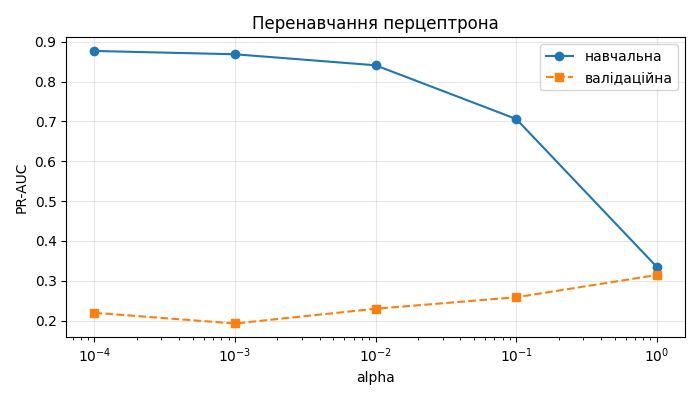

In [8]:
alphas = [0.0001, 0.001, 0.01, 0.1, 1.0]

rows = []
for alpha in alphas:
    m = MLPClassifier(hidden_layer_sizes=(32,), alpha=alpha, max_iter=1000, random_state=0)
    m.fit(X_tr, y_tr)
    tr_a = average_precision_score(y_tr, m.predict_proba(X_tr)[:, 1])
    va_a = average_precision_score(y_va, m.predict_proba(X_va)[:, 1])
    rows.append({"alpha": alpha, "PR-AUC train": tr_a, "PR-AUC val": va_a})

alpha_df = pd.DataFrame(rows).set_index("alpha")
print(alpha_df.to_string(float_format="{:.4f}".format))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(alpha_df.index, alpha_df["PR-AUC train"], "o-",  label="PR-AUC train")
ax.plot(alpha_df.index, alpha_df["PR-AUC val"],   "s--", label="PR-AUC val")
ax.set_xscale("log")
ax.set_xlabel("alpha")
ax.set_ylabel("PR-AUC")
ax.set_title("Перенавчання перцептрона")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Правило рішення

Модель дає ймовірність, а диспетчер має вирішити «їхати чи ні». Звичний поріг 0.5 означає «їхати, якщо відмова ймовірніша, ніж її відсутність». Але помилки коштують по-різному: зайвий виїзд — `COST_VISIT`, пропущена відмова — `COST_FAILURE`, у десятки разів дорожче. Тож виїзд виправданий і за значно меншої ймовірності.

Не поїхати до об'єкта з ймовірністю відмови p — у середньому втратити p · `COST_FAILURE`. Виїзд окупається, коли p · `COST_FAILURE` не менше за `COST_VISIT`, тобто коли p не менша за поріг `COST_VISIT / COST_FAILURE`.

Правило працює, лише якщо ймовірностям можна вірити: серед об'єктів з ймовірністю 0.1 має справді відмовляти близько 10%. Це називають **калібруванням** (calibration). Перша проста перевірка — середня ймовірність має бути близькою до частки відмов.

Ефект рішення — скільки гривень воно зберігає проти «нікого не перевіряти»:

- витрати «нікого не перевіряти» = кількість відмов · `COST_FAILURE`;
- витрати рішення = кількість виїздів · `COST_VISIT` + кількість об'єктів, що відмовили і до яких не виїхали, · `COST_FAILURE`;
- ефект = перше − друге.

1. Порахуйте поріг `COST_VISIT / COST_FAILURE` і ймовірності перцептрона з кроку 6 на `X_va`.
2. Виведіть поріг, середню ймовірність і частку відмов у `y_va`.
3. Виведіть таблицю для трьох правил — поріг з вартостей, поріг 0.5, перевірити всіх: скільки об'єктів на виїзд і ефект у гривнях. Ефект для трьох правил — одна функція від рішень, а не три копії формули. `y_va` після поділу має перемішаний індекс, тож рішення порівнюйте з `y_va.to_numpy()`.
4. Порівняйте три правила: яке зберігає найбільше і чому поріг 0.5 тут поганий — це відповідь для питання 3 звіту.

In [9]:
threshold = COST_VISIT / COST_FAILURE
proba_va  = models["перцептрон"].predict_proba(X_va)[:, 1]
y_va_np   = y_va.to_numpy()

print(f"Поріг: {threshold:.4f}")
print(f"Середня ймовірність: {proba_va.mean():.4f}")
print(f"Частка відмов y_va:  {y_va_np.mean():.4f}")

def cost_effect(decisions, y_true):
    n_visit        = decisions.sum()
    n_missed       = ((decisions == 0) & (y_true == 1)).sum()
    baseline_cost  = y_true.sum() * COST_FAILURE
    decision_cost  = n_visit * COST_VISIT + n_missed * COST_FAILURE
    return int(n_visit), int(baseline_cost), int(decision_cost), int(baseline_cost - decision_cost)

rules = [
    (f"поріг з вартостей = {threshold:.4f}", (proba_va >= threshold).astype(int)),
    ("поріг 0.5",                            (proba_va >= 0.5).astype(int)),
    ("перевірити всіх",                      np.ones(len(y_va_np), dtype=int)),
]

print(f"\n{'Правило':<32} {'На виїзд':>10} {'Без перевірки, грн':>20} {'Вартість рішення, грн':>22} {'Ефект, грн':>12}")
for label, dec in rules:
    n_vis, baseline, cost, eff = cost_effect(dec, y_va_np)
    print(f"{label:<32} {n_vis:>10} {baseline:>20,} {cost:>22,} {eff:>12,}")

Поріг: 0.0850
Середня ймовірність: 0.0618
Частка відмов y_va:  0.0584

Правило                           На виїзд   Без перевірки, грн   Вартість рішення, грн   Ефект, грн
поріг з вартостей = 0.0850             195            2,784,000               2,091,600      692,400
поріг 0.5                                7            2,784,000               2,572,560      211,440
перевірити всіх                        994            2,784,000               4,055,520   -1,271,520


## 9. Рішення й самоперевірка

Порахуйте ймовірності перцептрона з кроку 6 на `X_te` і рішення: 1, якщо ймовірність не менша за поріг з вартостей, інакше 0. Це рішення ви здаєте: викладач порахує, скільки гривень воно зберегло б на справжніх результатах об'єктів test.

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [10]:
proba_te = models["перцептрон"].predict_proba(X_te)[:, 1]
decision = (proba_te >= threshold).astype(int)

submission = pd.DataFrame({"object_id": test["object_id"], "decision": decision})

assert (COST_VISIT, COST_FAILURE) in [(1800, 60000), (2750, 50000), (4080, 48000), (5500, 50000)], "вартості — з таблиці README"
assert all(max(a, 1 - a) <= 0.9 for a in (roc_auc_score(y, X[c]) for c in X.columns)), "в ознаках лишилася колонка з AUC понад 0.9"
assert list(X_test.columns) == list(X.columns), "колонки X_test мають збігатися з X"
assert len(X_va) == int(np.ceil(len(train) * 0.25)), "валідаційна частина — 25% train"
assert np.allclose(np.mean(X_tr, axis=0), 0) and np.allclose(np.std(X_tr, axis=0), 1), "X_tr не стандартизовано"
assert len(submission) == len(test) and submission["object_id"].is_unique, "має бути рядок на кожен об'єкт test"
assert pd.api.types.is_integer_dtype(submission["decision"]) and submission["decision"].isin([0, 1]).all(), "decision — цілі 0 або 1, а не True/False"
assert 0.02 <= submission["decision"].mean() <= 0.9, "на виїзд менше 2% або більше 90% об'єктів: перевірте поріг"

submission.to_csv("submission.csv", index=False)

val_visit_rate  = (proba_va >= threshold).mean()
test_visit_rate = decision.mean()
print(f"усе гаразд")
print(f"об'єктів на виїзд у test: {decision.sum()} з {len(decision)} ({test_visit_rate:.1%})")
print(f"об'єктів на виїзд у val:  {int(val_visit_rate * len(y_va))} з {len(y_va)} ({val_visit_rate:.1%})")
print(f"різниця: {abs(test_visit_rate - val_visit_rate):.1%}")

усе гаразд
об'єктів на виїзд у test: 416 з 2025 (20.5%)
об'єктів на виїзд у val:  195 з 994 (19.6%)
різниця: 0.9%
